In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import numpy as np
import os

df_full = pd.read_csv('/kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv')

patients = df_full['Patient ID'].unique()
sampled_patients = pd.Series(patients).sample(frac=0.3, random_state=42)

df = df_full[df_full['Patient ID'].isin(sampled_patients)].reset_index(drop=True)

print(f"Full: {len(df_full)} images : {len(df)} images")

Full: 112120 images : 33554 images


In [2]:
needed_fnames = set(df['Image Index'])

image_path_map = {}
for i in range(1, 13):
    folder = f'/kaggle/input/datasets/nih-chest-xrays/data/images_{str(i).zfill(3)}/images'
    if os.path.exists(folder):
        for fname in os.listdir(folder):
            if fname in needed_fnames:
                image_path_map[fname] = os.path.join(folder, fname)

print(f"Sampled images mapped: {len(image_path_map)} / {len(needed_fnames)} expected")

Sampled images mapped: 33554 / 33554 expected


In [3]:
from sklearn.model_selection import train_test_split

unique_patients = df['Patient ID'].unique()
train_patients, val_patients = train_test_split(unique_patients, test_size=0.15, random_state=42)

train_fnames = df[df['Patient ID'].isin(train_patients)]['Image Index'].tolist()
val_fnames   = df[df['Patient ID'].isin(val_patients)]['Image Index'].tolist()

train_fnames = [f for f in train_fnames if f in image_path_map]
val_fnames   = [f for f in val_fnames if f in image_path_map]

print(f"Train: {len(train_fnames)} | Val: {len(val_fnames)}")

Train: 28610 | Val: 4944


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import random

class ChestXrayGridDataset(Dataset):
    def __init__(self, image_path_map, filenames, img_size=256,
                 grid_spacing=8, grid_intensity_range=(0.2, 0.5)):
        self.image_path_map       = image_path_map
        self.filenames            = filenames
        self.img_size             = img_size
        self.grid_spacing         = grid_spacing
        self.grid_intensity_range = grid_intensity_range

    def __len__(self):
        return len(self.filenames)

    def add_grid_artifact(self, image_np, grid_intensity):
        img = image_np.astype(np.float32) / 255.0
        H, W = img.shape
        grid_mask = np.zeros((H, W), dtype=np.float32)
        for y in range(0, H, self.grid_spacing):
            grid_mask[y:y+1, :] = 1.0
        dirty = img * (1.0 - grid_intensity * grid_mask)
        return dirty, img

    def __getitem__(self, idx):
        fname = self.filenames[idx]
        fpath = self.image_path_map[fname]

        img = Image.open(fpath).convert('L')
        img = img.resize((self.img_size, self.img_size), Image.BILINEAR)
        img_np = np.array(img)

        intensity = random.uniform(*self.grid_intensity_range)
        dirty, clean = self.add_grid_artifact(img_np, intensity)

        dirty_t = torch.tensor(dirty).unsqueeze(0).float()
        clean_t = torch.tensor(clean).unsqueeze(0).float()

        return dirty_t, clean_t

print("Dataset class defined")

Dataset class defined


In [7]:
train_dataset = ChestXrayGridDataset(image_path_map, train_fnames)
val_dataset   = ChestXrayGridDataset(image_path_map, val_fnames)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")

Train: 28610 | Val: 4944
Train batches: 895 | Val batches: 155


Total sampled:      33554
Pediatric (<18):    1477  (4.4%)
Adult (>=18):       32077


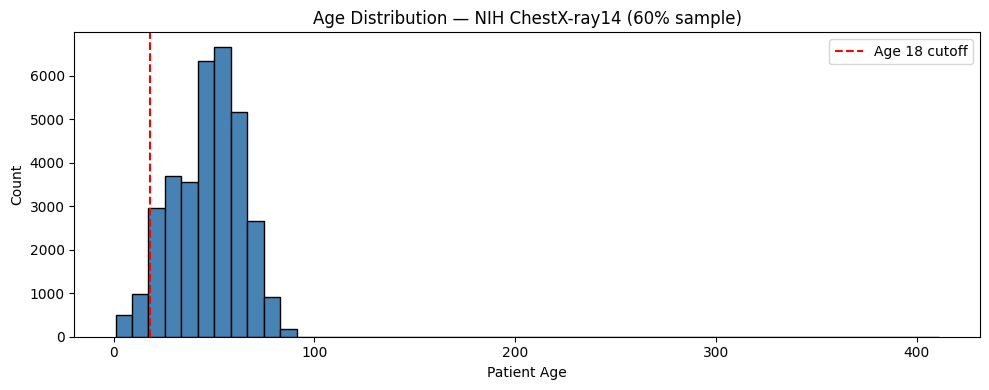

In [8]:
import matplotlib.pyplot as plt

df['Patient Age'] = pd.to_numeric(df['Patient Age'], errors='coerce')

pediatric = df[df['Patient Age'] < 18]
adult     = df[df['Patient Age'] >= 18]

print(f"Total sampled:      {len(df)}")
print(f"Pediatric (<18):    {len(pediatric)}  ({100*len(pediatric)/len(df):.1f}%)")
print(f"Adult (>=18):       {len(adult)}")

plt.figure(figsize=(10, 4))
plt.hist(df['Patient Age'].dropna(), bins=50, color='steelblue', edgecolor='black')
plt.axvline(18, color='red', linestyle='--', label='Age 18 cutoff')
plt.xlabel('Patient Age')
plt.ylabel('Count')
plt.title('Age Distribution — NIH ChestX-ray14 (60% sample)')
plt.legend()
plt.tight_layout()
plt.show()

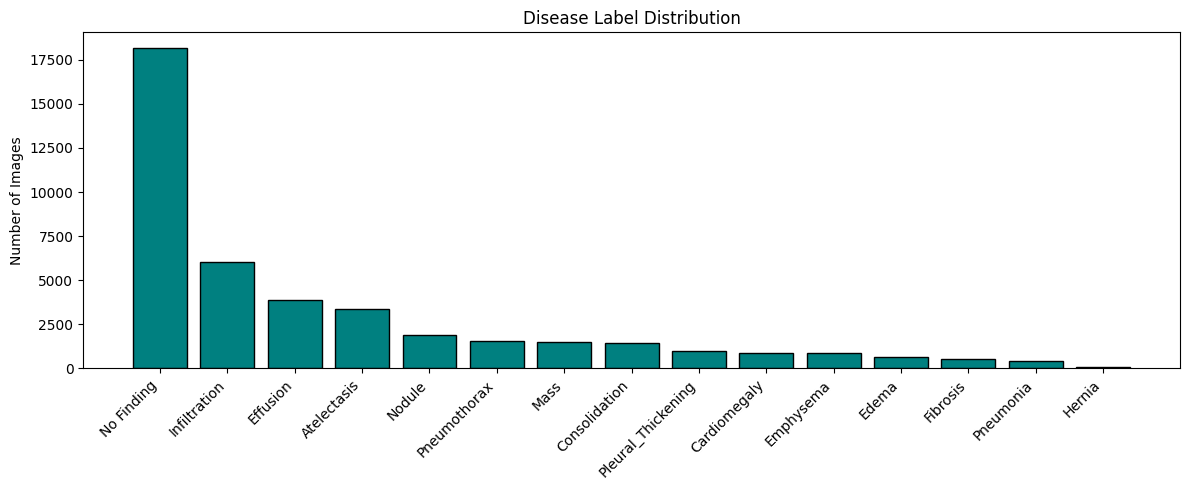

In [9]:
from collections import Counter

all_labels = []
for labels in df['Finding Labels']:
    all_labels.extend(labels.split('|'))

label_counts = Counter(all_labels)
label_df = pd.DataFrame(label_counts.items(), columns=['Label', 'Count']).sort_values('Count', ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(label_df['Label'], label_df['Count'], color='teal', edgecolor='black')
plt.xticks(rotation=45, ha='right')
plt.title('Disease Label Distribution')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

def fourier_grid_removal(img, grid_spacing=8, band_width=2):
    """Removes periodic horizontal-grid frequency component via FFT notch filter."""
    F = np.fft.fft2(img)
    Fshift = np.fft.fftshift(F)
    H, W = img.shape
    cy, cx = H // 2, W // 2

    freq = H / grid_spacing
    row1 = int(round(cy + freq))
    row2 = int(round(cy - freq))

    mask = np.ones((H, W), dtype=np.float32)
    for r in [row1, row2]:
        r0, r1 = max(0, r - band_width), min(H, r + band_width + 1)
        mask[r0:r1, :] = 0.0
    mask[cy-1:cy+2, cx-1:cx+2] = 1.0  # keep DC term (overall brightness)

    Fshift_filtered = Fshift * mask
    F_filtered = np.fft.ifftshift(Fshift_filtered)
    img_filtered = np.abs(np.fft.ifft2(F_filtered))
    return np.clip(img_filtered, 0, 1).astype(np.float32)

# Sanity check on one real batch from val_loader
dirty_batch, clean_batch = next(iter(val_loader))
d = dirty_batch[0, 0].numpy()
c = clean_batch[0, 0].numpy()
restored = fourier_grid_removal(d, grid_spacing=8)

print(f"Dirty MSE:    {np.mean((d - c)**2):.6f}")
print(f"Restored MSE: {np.mean((restored - c)**2):.6f}")

In [ ]:
sample_files = df['Image Index'].values[:9]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, fname in zip(axes.flatten(), sample_files):
    if fname in image_path_map:
        img = Image.open(image_path_map[fname]).convert('L')
        ax.imshow(img, cmap='gray')
        label = df[df['Image Index'] == fname]['Finding Labels'].values[0]
        age   = df[df['Image Index'] == fname]['Patient Age'].values[0]
        ax.set_title(f"Age:{age}\n{label[:30]}", fontsize=8)
    ax.axis('off')

plt.suptitle('Sample NIH Chest X-ray Images (sampled set)', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
!pip install segmentation-models-pytorch -q
import torch.nn as nn
import segmentation_models_pytorch as smp

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

model = smp.Unet(
    encoder_name='resnet34',
    encoder_weights='imagenet',
    in_channels=1,
    classes=1,
    activation='sigmoid'
)
model = model.to(device)

if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs")
    model = nn.DataParallel(model)

print("Model built")

In [ ]:
!pip install pytorch-msssim -q
from pytorch_msssim import ssim

def combined_loss(pred, target, alpha=0.5):
    mse = nn.MSELoss()(pred, target)
    ssim_val = ssim(pred, target, data_range=1.0, size_average=True)
    return alpha * (1 - ssim_val) + (1 - alpha) * mse

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

print("Loss, optimizer, scheduler ready")

In [11]:

from tqdm.notebook import tqdm

NUM_EPOCHS = 15
best_val_loss = float('inf')

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [train]")
    for dirty, clean in train_bar:
        dirty, clean = dirty.to(device), clean.to(device)
        pred = model(dirty)
        loss = combined_loss(pred, clean)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_bar.set_postfix(loss=f"{loss.item():.4f}")
    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [val]")
    with torch.no_grad():
        for dirty, clean in val_bar:
            dirty, clean = dirty.to(device), clean.to(device)
            pred = model(dirty)
            loss = combined_loss(pred, clean)
            val_loss += loss.item()
            val_bar.set_postfix(loss=f"{loss.item():.4f}")
    val_loss /= len(val_loader)

    scheduler.step(val_loss)
    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        state_dict = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
        torch.save(state_dict, 'best_unet_resnet34.pth')
        print(f"  Best model saved (val_loss={val_loss:.4f})")

Epoch 1/15 [train]:   0%|          | 0/895 [00:00<?, ?it/s]

Epoch 1/15 [val]:   0%|          | 0/155 [00:00<?, ?it/s]

Epoch [01/15] | Train Loss: 0.0297 | Val Loss: 0.0090
  Best model saved (val_loss=0.0090)


Epoch 2/15 [train]:   0%|          | 0/895 [00:00<?, ?it/s]

Epoch 2/15 [val]:   0%|          | 0/155 [00:00<?, ?it/s]

...

Epoch 14/15 [val]:   0%|          | 0/155 [00:00<?, ?it/s]

Epoch [14/15] | Train Loss: 0.0020 | Val Loss: 0.0065


Epoch 15/15 [train]:   0%|          | 0/895 [00:00<?, ?it/s]

Epoch 15/15 [val]:   0%|          | 0/155 [00:00<?, ?it/s]

Epoch [15/15] | Train Loss: 0.0020 | Val Loss: 0.0033


In [13]:
checkpoint_path = '/kaggle/input/models/logicexerpvtltd/resnet/pytorch/default/1/best_unet_resnet34.pth'  # update after upload

state_dict = torch.load(checkpoint_path, map_location=device)
if isinstance(model, nn.DataParallel):
    model.module.load_state_dict(state_dict)
else:
    model.load_state_dict(state_dict)

model.eval()
print("Checkpoint loaded")

Checkpoint loaded


In [14]:
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim_sk
import numpy as np

nih_psnr_dirty, nih_psnr_pred = [], []
nih_ssim_dirty, nih_ssim_pred = [], []

model.eval()
with torch.no_grad():
    for dirty, clean in val_loader:
        dirty, clean = dirty.to(device), clean.to(device)
        pred = model(dirty)

        dirty_np = dirty.cpu().squeeze(1).numpy()
        clean_np = clean.cpu().squeeze(1).numpy()
        pred_np  = pred.cpu().squeeze(1).numpy()

        for i in range(len(dirty_np)):
            d, c, p = dirty_np[i], clean_np[i], pred_np[i]
            nih_psnr_dirty.append(psnr(c, d, data_range=1.0))
            nih_psnr_pred.append(psnr(c, p, data_range=1.0))
            nih_ssim_dirty.append(ssim_sk(c, d, data_range=1.0))
            nih_ssim_pred.append(ssim_sk(c, p, data_range=1.0))

print("NIH Validation (same domain as training)")
print(f"{'Metric':<20} {'Dirty (input)':<20} {'Predicted (output)'}")
print(f"{'PSNR':<20} {np.mean(nih_psnr_dirty):<20.4f} {np.mean(nih_psnr_pred):.4f}")
print(f"{'SSIM':<20} {np.mean(nih_ssim_dirty):<20.4f} {np.mean(nih_ssim_pred):.4f}")


NIH Validation (same domain as training)
Metric               Dirty (input)        Predicted (output)
PSNR                 23.7388              40.6973
SSIM                 0.5236               0.9938


In [15]:
BASE = '/kaggle/input/datasets/cellercity/vindr-pcxr-zipped'
vindr_test_dir = os.path.join(BASE, 'png_images', 'png_images', 'test')

vindr_test_files = [f for f in os.listdir(vindr_test_dir) if f.endswith('.png')]
vindr_image_path_map = {f: os.path.join(vindr_test_dir, f) for f in vindr_test_files}

vindr_dataset = ChestXrayGridDataset(vindr_image_path_map, vindr_test_files)
vindr_loader  = DataLoader(vindr_dataset, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)

print(f"VinDr-PCXR eval set: {len(vindr_dataset)} images | {len(vindr_loader)} batches")

VinDr-PCXR eval set: 1397 images | 44 batches


In [18]:
from tqdm.notebook import tqdm
vindr_psnr_dirty, vindr_psnr_pred = [], []
vindr_ssim_dirty, vindr_ssim_pred = [], []

model.eval()
with torch.no_grad():
    for dirty, clean in tqdm(vindr_loader, desc="VinDr-PCXR eval"):
        dirty, clean = dirty.to(device), clean.to(device)
        pred = model(dirty)

        dirty_np = dirty.cpu().squeeze(1).numpy()
        clean_np = clean.cpu().squeeze(1).numpy()
        pred_np  = pred.cpu().squeeze(1).numpy()

        for i in range(len(dirty_np)):
            d, c, p = dirty_np[i], clean_np[i], pred_np[i]
            vindr_psnr_dirty.append(psnr(c, d, data_range=1.0))
            vindr_psnr_pred.append(psnr(c, p, data_range=1.0))
            vindr_ssim_dirty.append(ssim_sk(c, d, data_range=1.0))
            vindr_ssim_pred.append(ssim_sk(c, p, data_range=1.0))

print("VinDr-PCXR (pediatric, unseen domain)")
print(f"{'Metric':<20} {'Dirty (input)':<20} {'Predicted (output)'}")
print(f"{'PSNR':<20} {np.mean(vindr_psnr_dirty):<20.4f} {np.mean(vindr_psnr_pred):.4f}")
print(f"{'SSIM':<20} {np.mean(vindr_ssim_dirty):<20.4f} {np.mean(vindr_ssim_pred):.4f}")

print(f"\nComparison to NIH validation:")
print(f"{'Metric':<20} {'NIH (source)':<20} {'VinDr-PCXR (target)'}")
print(f"{'PSNR':<20} {np.mean(nih_psnr_pred):<20.4f} {np.mean(vindr_psnr_pred):.4f}")
print(f"{'SSIM':<20} {np.mean(nih_ssim_pred):<20.4f} {np.mean(vindr_ssim_pred):.4f}")

VinDr-PCXR eval:   0%|          | 0/44 [00:00<?, ?it/s]

VinDr-PCXR (pediatric, unseen domain)
Metric               Dirty (input)        Predicted (output)
PSNR                 22.9648              39.2262
SSIM                 0.4857               0.9906

Comparison to NIH validation:
Metric               NIH (source)         VinDr-PCXR (target)
PSNR                 40.6973              39.2262
SSIM                 0.9938               0.9906


Saved: /kaggle/working/comparison_nih.png


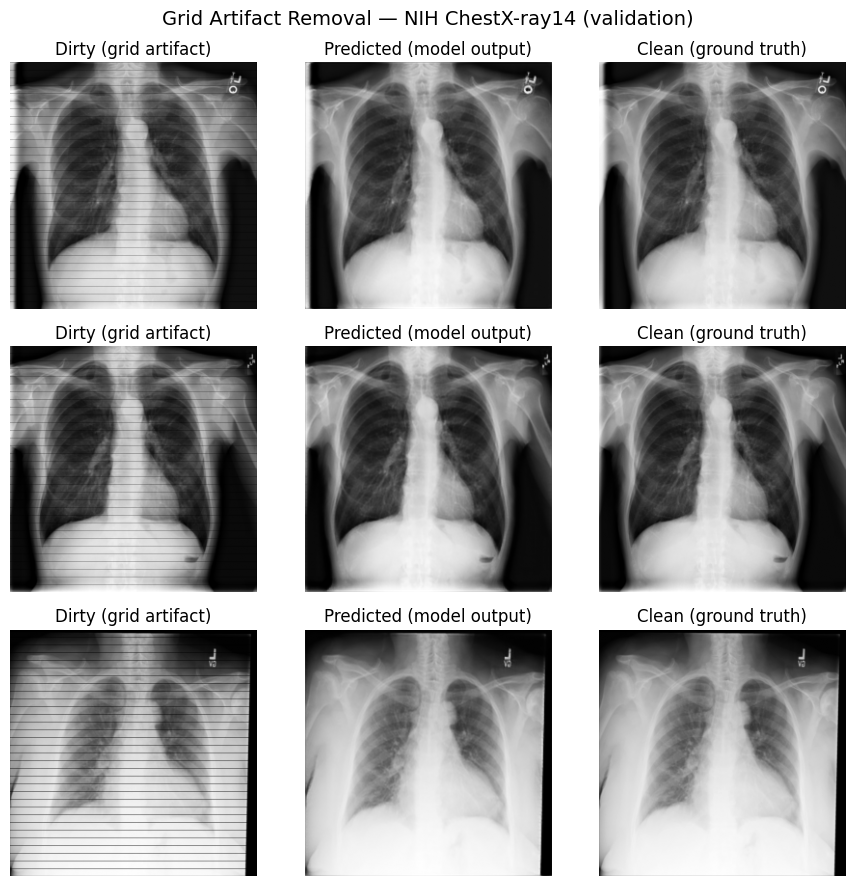

Saved: /kaggle/working/comparison_vindr.png


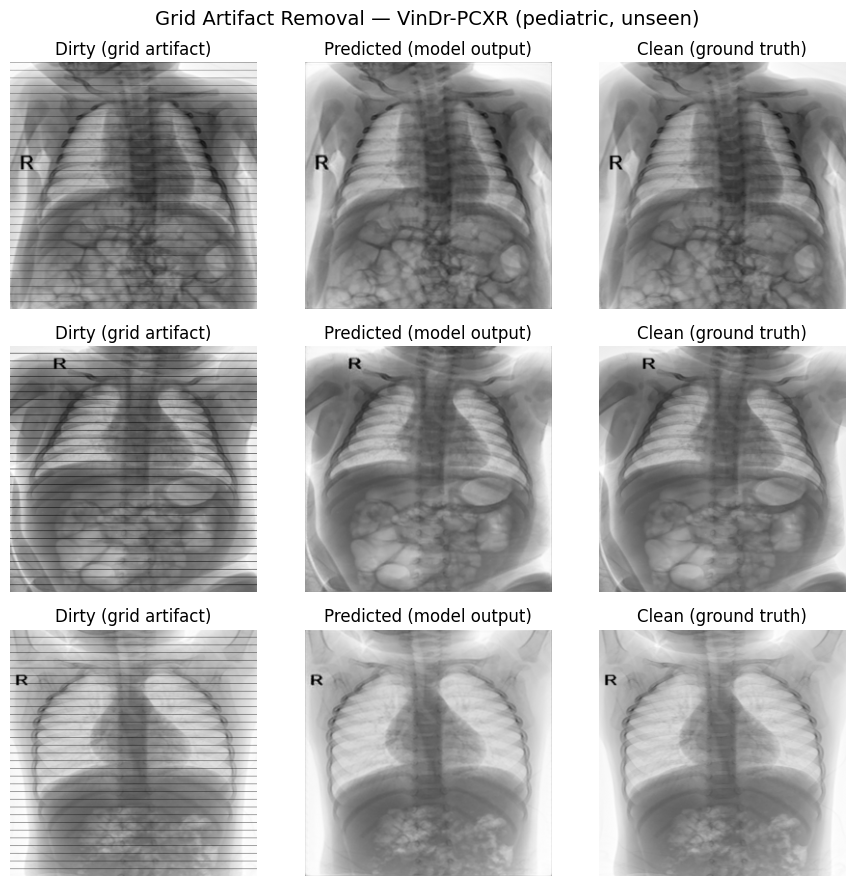

In [19]:
import matplotlib.pyplot as plt

def show_comparison(loader, dataset_name, n_samples=3, save_path=None):
    model.eval()
    dirty_batch, clean_batch = next(iter(loader))
    dirty_batch, clean_batch = dirty_batch.to(device), clean_batch.to(device)
    with torch.no_grad():
        pred_batch = model(dirty_batch)

    fig, axes = plt.subplots(n_samples, 3, figsize=(9, 3 * n_samples))
    for i in range(n_samples):
        d = dirty_batch[i, 0].cpu().numpy()
        p = pred_batch[i, 0].cpu().numpy()
        c = clean_batch[i, 0].cpu().numpy()
        axes[i, 0].imshow(d, cmap='gray'); axes[i, 0].set_title('Dirty (grid artifact)'); axes[i, 0].axis('off')
        axes[i, 1].imshow(p, cmap='gray'); axes[i, 1].set_title('Predicted (model output)'); axes[i, 1].axis('off')
        axes[i, 2].imshow(c, cmap='gray'); axes[i, 2].set_title('Clean (ground truth)'); axes[i, 2].axis('off')

    plt.suptitle(f'Grid Artifact Removal — {dataset_name}', fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved: {save_path}")
    plt.show()

show_comparison(val_loader,   'NIH ChestX-ray14 (validation)', n_samples=3, save_path='/kaggle/working/comparison_nih.png')
show_comparison(vindr_loader, 'VinDr-PCXR (pediatric, unseen)', n_samples=3, save_path='/kaggle/working/comparison_vindr.png')

In [20]:
import pandas as pd

results = pd.DataFrame({
    'Dataset':   ['NIH ChestX-ray14 (val)', 'VinDr-PCXR (pediatric)'],
    'PSNR_dirty': [np.mean(nih_psnr_dirty), np.mean(vindr_psnr_dirty)],
    'PSNR_pred':  [np.mean(nih_psnr_pred),  np.mean(vindr_psnr_pred)],
    'SSIM_dirty': [np.mean(nih_ssim_dirty), np.mean(vindr_ssim_dirty)],
    'SSIM_pred':  [np.mean(nih_ssim_pred),  np.mean(vindr_ssim_pred)],
})

results.to_csv('/kaggle/working/final_results.csv', index=False)
print(results)

                  Dataset  PSNR_dirty  PSNR_pred  SSIM_dirty  SSIM_pred
0  NIH ChestX-ray14 (val)    23.73879  40.697339    0.523607   0.993761
1  VinDr-PCXR (pediatric)    22.96480  39.226150    0.485743   0.990619
